# Travel times and rays with pykonal in the rainier3d velocity model

This notebook computes P and S travel times and ray paths from an earthquake to a set of stations in the
rainier3d model of Mount Rainier, with the eikonal solver [pykonal](https://github.com/malcolmw/pykonal)
(White et al. 2020). It uses the same set-up as the pipeline's own travel times (stages S6, S13 and S37), and
compares the result with the analyst picks of the event.

**What you need.**
- The package and pykonal: `pip install "git+https://github.com/Denolle-Lab/mt-rainier-digital-model" pykonal`,
  or `pixi run jupyter lab` inside the repository.
- About 2 GB of memory and a minute of run time at 250 m spacing.
- The model is downloaded once, about 200 MB.

**Steps.** (1) load the model, (2) set the source and receivers, (3) build a velocity grid with air above the
ground, (4) solve the eikonal equation, (5) read the times at the receivers, (6) compare with the picks,
(7) trace the rays.

The model itself (contents, coordinates, what it resolves) is described in `docs/velocity_model.md`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pykonal
from pyproj import Transformer
from scipy.ndimage import map_coordinates

import rainier3d.api as r3

## 1. Load the model

`r3.open_model()` downloads the published model once and returns an xarray DataTree. `product="model_let"`
gives the model after the local-earthquake tomography, which fits travel times near the network better
(`docs/velocity_model.md`, Sect. 1). Inside the repository, point `STORE` at `data/processed/model.zarr` to use
the model you built.

In [2]:
PRODUCT = "model"  # or "model_let"
STORE = None  # e.g. "data/processed/model.zarr" inside the repository

tree = r3.open_model(STORE) if STORE else r3.open_model(product=PRODUCT)
print(tree.attrs["crs"], tree.attrs["vertical_datum"])
print("calibration:", tree["L1"].attrs.get("vs_calibration"))

EPSG:32610 EPSG:5703
calibration: configs/velocity_calibration.yaml (2026-10-27)


## 2. Source and receivers

The model frame is UTM zone 10N in metres. Vertically, pykonal works with depth $d = -z$, positive down, where
$z$ is the NAVD88 elevation. So a station at 3077 m elevation has $d = -3077$ m, and an earthquake 11.05 km below
sea level has $d = 11050$ m. ComCat depths are below sea level.

The example is ComCat event uw61057477, an M 2.8 earthquake in the West Rainier Seismic Zone, with its PNSN
analyst picks. The observed times are relative to the ComCat origin time; `NaN` means no pick. To use your own
geometry, replace the two tables, or read a CSV with columns `code, lon, lat, elev_m`.

In [3]:
SOURCE = dict(lon=-122.178833, lat=46.754000, depth_km=11.05)  # ComCat uw61057477, M 2.8

receivers = pd.DataFrame(
    [  # code, lon, lat, elevation (m), observed P and S travel times (s, PNSN analyst picks)
        ("CC.OBSR", -121.815331, 46.899719, 2382.0, 5.75, 10.25),
        ("CC.PANH", -121.642592, 46.859032, 2086.0, 7.11, 12.57),
        ("UW.FMW", -121.671465, 46.941914, 1897.0, 7.30, np.nan),
        ("UW.GHW", -122.273727, 47.041489, 261.1, 5.54, 9.82),
        ("UW.GLK", -121.610733, 46.557499, 1305.0, 8.23, np.nan),
        ("UW.LON", -121.809601, 46.750599, 853.0, 5.01, 8.83),
        ("UW.PCEP", -122.291220, 47.111400, 158.0, 6.99, np.nan),
        ("UW.RCM", -121.733180, 46.835570, 3077.0, 6.20, 10.80),
        ("UW.RCS", -121.732310, 46.870830, 2877.0, 6.26, np.nan),
        ("UW.RER", -121.842500, 46.818580, 1751.1, 4.84, np.nan),
        ("UW.RVC", -121.974190, 46.944080, 1000.0, 4.87, np.nan),
        ("UW.STAR", -121.792953, 46.850849, 3365.0, 5.68, 9.99),
    ],
    columns=["code", "lon", "lat", "elev_m", "obs_P", "obs_S"],
)

to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32610", always_xy=True)
receivers["x"], receivers["y"] = to_utm.transform(receivers.lon.values, receivers.lat.values)
receivers["d"] = -receivers.elev_m
sx, sy = to_utm.transform(SOURCE["lon"], SOURCE["lat"])
src = np.array([sx, sy, SOURCE["depth_km"] * 1e3])  # (x, y, d) in metres
receivers.round(1)

,code,lon,lat,elev_m,obs_P,obs_S,x,y,d
0,CC.OBSR,-121.8,46.9,2382.0,5.8,10.2,590233.1,5194701.5,-2382.0
1,CC.PANH,-121.6,46.9,2086.0,7.1,12.6,603468.2,5190393.4,-2086.0
2,UW.FMW,-121.7,46.9,1897.0,7.3,NaN,601111.4,5199565.9,-1897.0
3,UW.GHW,-122.3,47.0,261.1,5.5,9.8,555172.5,5210030.6,-261.1
4,UW.GLK,-121.6,46.6,1305.0,8.2,NaN,606488.1,5156929.9,-1305.0
5,UW.LON,-121.8,46.8,853.0,5.0,8.8,590920.6,5178137.7,-853.0
6,UW.PCEP,-122.3,47.1,158.0,7.0,NaN,553773.2,5217787.4,-158.0
7,UW.RCM,-121.7,46.8,3077.0,6.2,10.8,596605.3,5187670.9,-3077.0
8,UW.RCS,-121.7,46.9,2877.0,6.3,NaN,596608.4,5191590.1,-2877.0
9,UW.RER,-121.8,46.8,1751.1,4.8,NaN,588296.7,5185654.3,-1751.1


## 3. A velocity grid with air above the ground

pykonal needs cubic cells: the same spacing in x, y and z. The model's own levels have different spacings
(250 m × 50 m above sea level, 500 m × 250 m to −6 km, 1 km below), so `r3.grid` resamples all three onto one
uniform grid. `air` flags the cells above the ground, which hold the rock value below them.

**Air.** If the air kept rock velocities, rays could cross valleys through the air at rock speed. So cells more
than one cell above the ground get the speed of sound, 343 m/s. The first cell above the ground keeps the rock
value (the *skin*), so stations whose elevation is a few tens of metres off the DEM still sit in rock. This is
`rainier3d.validate.locate.with_topography` with `skin_cells = 1`.

**Spacing.** Against analytic solutions on a grid of this size, pykonal's RMS error is 8 ms in a uniform model
and 11 ms in a gradient model at 500 m spacing, and 4.7 and 5.7 ms at 250 m, at about nine times the cost
(`docs/eikonal_benchmark.md`). Use 500 m for many sources and 250 m for a few.

**Region.** The grid is cut to the source and receivers plus a margin, to save time.

In [4]:
DX = 250.0  # m, the same in x, y and z
MARGIN = 10e3  # m around the source and the receivers
AIR_V = 343.0  # m/s

xs, ys = np.r_[receivers.x, sx], np.r_[receivers.y, sy]
t0 = time.time()
g = r3.grid(tree, dx=DX, dz=DX, zmin=-(src[2] + MARGIN), variables=("vp", "vs"))  # z descending
g = g.sel(x=slice(xs.min() - MARGIN, xs.max() + MARGIN), y=slice(ys.min() - MARGIN, ys.max() + MARGIN))

air = g.air.values.astype(bool)  # (z, y, x)
below_is_ground = np.zeros_like(air)
below_is_ground[:-1] = ~air[1:]  # index k + 1 is the cell below k
sky = air & ~below_is_ground  # air more than one cell above the ground
vel = {ph: np.where(sky, AIR_V, g[v].values).astype(float) for ph, v in (("P", "vp"), ("S", "vs"))}
print(f"{g.x.size} x {g.y.size} x {g.z.size} nodes at {DX:.0f} m in {time.time() - t0:.0f} s")

254 x 300 x 102 nodes at 250 m in 2 s


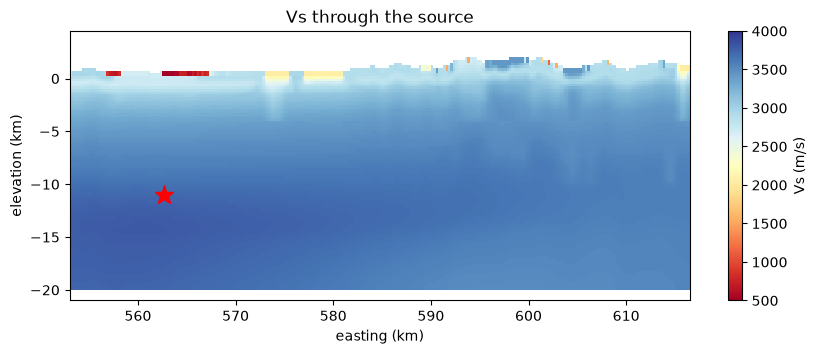

In [5]:
# Vs on a west-east section through the source, with the air (343 m/s) masked
iy = int(np.argmin(np.abs(g.y.values - sy)))
fig, ax = plt.subplots(figsize=(10, 3.5))
v = np.ma.masked_where(sky[:, iy, :], vel["S"][:, iy, :])
im = ax.pcolormesh(g.x / 1e3, g.z / 1e3, v, cmap="RdYlBu", vmin=500, vmax=4000, shading="nearest")
ax.plot(sx / 1e3, -src[2] / 1e3, "r*", ms=14)
ax.set(xlabel="easting (km)", ylabel="elevation (km)", title="Vs through the source")
fig.colorbar(im, ax=ax, label="Vs (m/s)");

## 4. Solve the eikonal equation

One `PointSourceSolver` per phase, in Cartesian coordinates. Its velocity array is ordered (x, y, d) with every
axis ascending. Because the grid's z axis is descending, d = −z is already ascending, so a transpose is enough.

In [6]:
def solve(vel_zyx, g, src_xyd):
    s = pykonal.solver.PointSourceSolver(coord_sys="cartesian")
    s.velocity.min_coords = g.x.values[0], g.y.values[0], -g.z.values[0]
    s.velocity.node_intervals = DX, DX, DX
    s.velocity.npts = g.x.size, g.y.size, g.z.size
    s.velocity.values = np.ascontiguousarray(np.transpose(vel_zyx, (2, 1, 0)))  # (x, y, d)
    s.src_loc = np.asarray(src_xyd, float)
    s.solve()
    return s


sol = {}
for ph in ("P", "S"):
    t0 = time.time()
    sol[ph] = solve(vel[ph], g, src)
    print(f"{ph}: {time.time() - t0:.1f} s")

P: 10.8 s


S: 11.0 s


## 5. Times at the receivers

The travel-time field is sampled at each receiver by trilinear interpolation.

In [7]:
def times_at(s, pts_xyd):
    o, dx = np.asarray(s.velocity.min_coords), np.asarray(s.velocity.node_intervals)
    idx = ((np.atleast_2d(pts_xyd) - o) / dx).T
    return map_coordinates(s.traveltime.values, idx, order=1, mode="nearest")


pts = receivers[["x", "y", "d"]].values
for ph in ("P", "S"):
    receivers[f"t{ph}"] = times_at(sol[ph], pts)
receivers["epicentral_km"] = np.hypot(receivers.x - sx, receivers.y - sy) / 1e3
receivers[["code", "epicentral_km", "tP", "obs_P", "tS", "obs_S"]].round(3)

,code,epicentral_km,tP,obs_P,tS,obs_S
0,CC.OBSR,32.109,5.998,5.75,10.326,10.25
1,CC.PANH,42.551,7.424,7.11,12.768,12.57
2,UW.FMW,43.962,7.699,7.30,13.245,NaN
3,UW.GHW,32.756,5.553,5.54,10.194,9.82
4,UW.GLK,48.647,8.398,8.23,14.465,NaN
5,UW.LON,28.205,5.213,5.01,8.953,8.83
6,UW.PCEP,40.629,6.907,6.99,12.531,NaN
7,UW.RCM,35.200,6.505,6.20,11.167,10.80
8,UW.RCS,36.459,6.655,6.26,11.405,NaN
9,UW.RER,26.658,5.081,4.84,8.744,NaN


## 6. Compare with the picks

The ComCat hypocentre and origin time come from a location in a one-dimensional model. Any error in the origin
time, and much of any error in the source depth, shifts every predicted time by about the same amount. So
remove the mean residual of each phase before judging the model; what remains is what a 3D relocation would
start from. At ComCat hypocentres, the paper finds the 3D model's P times later than the 1D model's by 0.31 s
on average, and the RMS of the event-demeaned residuals is 0.133 s for P and 0.228 s for S (stage S6).

P: 12 picks, mean residual -0.218 s, RMS after removing it 0.143 s
S: 6 picks, mean residual -0.251 s, RMS after removing it 0.124 s


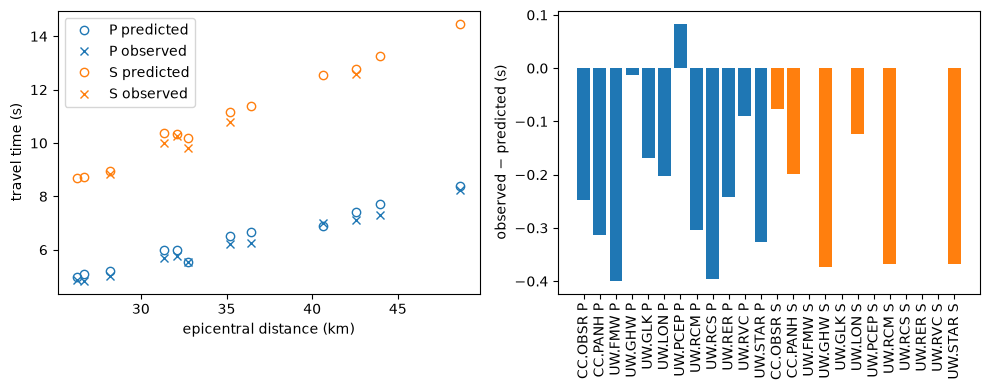

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for ph, col in (("P", "C0"), ("S", "C1")):
    r = (receivers[f"obs_{ph}"] - receivers[f"t{ph}"]).dropna()
    rms = float(np.sqrt(((r - r.mean()) ** 2).mean()))
    print(f"{ph}: {r.size} picks, mean residual {r.mean():+.3f} s, RMS after removing it {rms:.3f} s")
    d = receivers.epicentral_km
    ax[0].plot(d, receivers[f"t{ph}"], "o", mfc="none", color=col, label=f"{ph} predicted")
    ax[0].plot(d, receivers[f"obs_{ph}"], "x", color=col, label=f"{ph} observed")
    ax[1].bar(receivers.code + f" {ph}", receivers[f"obs_{ph}"] - receivers[f"t{ph}"], color=col)
ax[0].set(xlabel="epicentral distance (km)", ylabel="travel time (s)")
ax[0].legend()
ax[1].set(ylabel="observed − predicted (s)")
ax[1].tick_params(axis="x", rotation=90)
fig.tight_layout()

## 7. Ray paths

A ray runs down the gradient of the travel-time field, from the receiver back to the source. The tracer below
takes steps of a quarter cell and closes the last two cells with a straight segment, as the pipeline does
(`rainier3d.validate.locate.trace_rays`). pykonal's own `trace_ray` fails with NumPy 2 in pykonal 0.4.1, so it is
not used here.

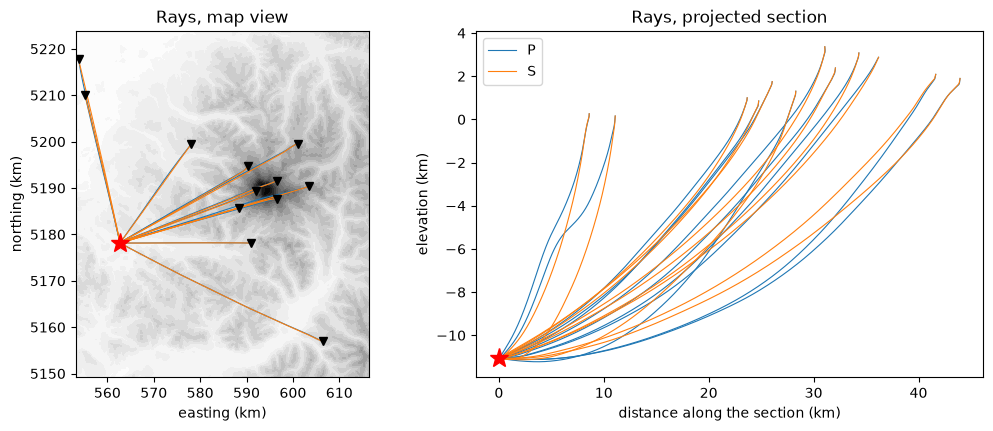

In [9]:
def trace_ray(s, end_xyd):
    o, dx = np.asarray(s.velocity.min_coords), float(s.velocity.node_intervals[0])
    if not hasattr(s, "_grad"):
        with np.errstate(invalid="ignore"):  # unreached nodes hold inf
            s._grad = np.gradient(s.traveltime.values, dx)  # dT/dx, dT/dy, dT/dd at the nodes
    src = np.asarray(s.src_loc, float)
    pos = np.asarray(end_xyd, float)
    path = [pos]
    for _ in range(int(40 * np.linalg.norm(pos - src) / dx) + 10):
        if np.linalg.norm(pos - src) < 2 * dx:
            break
        idx = ((pos - o) / dx)[:, None]
        grad = np.array([map_coordinates(c, idx, order=1, mode="nearest")[0] for c in s._grad])
        pos = pos - dx / 4 * grad / max(np.linalg.norm(grad), 1e-12)
        path.append(pos)
    return np.array(path + [src])


surf = (
    tree["surface"]
    .to_dataset()
    .elevation.sel(x=slice(g.x.values[0], g.x.values[-1]), y=slice(g.y.values[0], g.y.values[-1]))
)
az = np.arctan2(receivers.y.mean() - sy, receivers.x.mean() - sx)  # section towards the receivers
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
ax[0].contourf(surf.x / 1e3, surf.y / 1e3, surf.values, levels=20, cmap="Greys")
for ph, col in (("P", "C0"), ("S", "C1")):
    for i, r in enumerate(receivers.itertuples()):
        ray = trace_ray(sol[ph], np.array([r.x, r.y, r.d]))
        ax[0].plot(ray[:, 0] / 1e3, ray[:, 1] / 1e3, color=col, lw=0.8)
        along = ((ray[:, 0] - sx) * np.cos(az) + (ray[:, 1] - sy) * np.sin(az)) / 1e3
        ax[1].plot(along, -ray[:, 2] / 1e3, color=col, lw=0.8, label=ph if i == 0 else None)
for a in ax:
    a.plot(*((sx / 1e3, sy / 1e3) if a is ax[0] else (0, -src[2] / 1e3)), "r*", ms=14)
ax[0].plot(receivers.x / 1e3, receivers.y / 1e3, "kv")
ax[0].set(xlabel="easting (km)", ylabel="northing (km)", aspect="equal", title="Rays, map view")
ax[1].set(xlabel="distance along the section (km)", ylabel="elevation (km)", title="Rays, projected section")
ax[1].legend();

## Going further

- **Many earthquakes.** By reciprocity, the time from a source to a station equals the time from the station to
  the source. Solve once per station and phase, keep the fields, and sample them at any hypocentre: the
  pipeline does this in `rainier3d.validate.locate.fields`.
- **Another model.** Set `PRODUCT = "model_let"` to compare with the model after the tomography.
- **Locating earthquakes.** Use `rainier3d.validate.locate`, or NonLinLoc with the ready-made grids
  (`rainier3d fetch grids`; settings in `docs/products.md`).
- **Common mistakes.**
  - Depth sign: d is positive down, z is the elevation, and ComCat depths are below sea level.
  - Station elevation: use the instrument elevation, including borehole depth.
  - Grid spacing: x, y and z must have the same spacing.
  - Grid extent: the grid must contain the source, every receiver and the region the rays can use; a 10 km
    margin is safe here.